In [2]:
# ============================================================
# NOTEBOOK 01 — DATASET EXPLORATION
# SETUP & ENVIRONMENT INITIALIZATION
# ============================================================

from pathlib import Path
import os
import sys

# Safe dynamic path resolution (works on Windows, Linux, and Google Colab)
try:
    from google.colab import drive
    if Path('/content').exists():
        drive.mount('/content/drive')
        PROJECT_DIR = Path('/content/drive/MyDrive/AI-Cybersecurity-Assistant')
    else:
        PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
except Exception:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

print(f"Project root directory: {PROJECT_DIR}")


Mounted at /content/drive


**Dataset_exploration**

In [8]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

In [10]:
# Verify project directories
print("Project directory contents:")
print(os.listdir(PROJECT_DIR))


['notebooks', 'data']


In [12]:
DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "raw",
    "CIC-IDS2017"
)

NEW_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "new notebook results"
)

PICTURES_DIR = os.path.join(NEW_RESULTS_DIR, "pictures")
TABLES_DIR = os.path.join(NEW_RESULTS_DIR, "tables")

for d in [PICTURES_DIR, TABLES_DIR]:
    os.makedirs(d, exist_ok=True)

print("Data directory:", DATA_DIR)
print("Data directory exists:", os.path.exists(DATA_DIR))


Project directory:
/content/drive/MyDrive/AI-Cybersecurity-Assistant

Dataset directory:
/content/drive/MyDrive/AI-Cybersecurity-Assistant/data/raw/CIC-IDS2017

Dataset directory exists:
True


In [13]:
csv_files = sorted(
    glob.glob(
        os.path.join(DATA_DIR, "*.csv")
    )
)

print("Number of CSV files:", len(csv_files))
print()

for i, file in enumerate(csv_files, start=1):

    size_gb = os.path.getsize(file) / (1024 ** 3)

    print(
        f"{i}. {os.path.basename(file)}"
        f" --> {size_gb:.2f} GB"
    )

Number of CSV files: 8

1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv --> 0.07 GB
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv --> 0.07 GB
3. Friday-WorkingHours-Morning.pcap_ISCX.csv --> 0.05 GB
4. Monday-WorkingHours.pcap_ISCX.csv --> 0.16 GB
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv --> 0.08 GB
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv --> 0.05 GB
7. Tuesday-WorkingHours.pcap_ISCX.csv --> 0.13 GB
8. Wednesday-workingHours.pcap_ISCX.csv --> 0.21 GB


In [14]:
pd.concat(
    [pd.read_csv(file) for file in csv_files]
)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.00000,0,0,0.0,0.0,4.000000e+06,666666.666700,3.0,0.000000,3,3,3,3.00000,0.00000,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,9.000000,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.00000,6,6,6.0,0.0,1.100917e+05,18348.623850,109.0,0.000000,109,109,0,0.00000,0.00000,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,9.000000,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.00000,6,6,6.0,0.0,2.307692e+05,38461.538460,52.0,0.000000,52,52,0,0.00000,0.00000,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,9.000000,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.00000,6,6,6.0,0.0,3.529412e+05,58823.529410,34.0,0.000000,34,34,0,0.00000,0.00000,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,1,9.000000,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.00000,0,0,0.0,0.0,4.000000e+06,666666.666700,3.0,0.000000,3,3,3,3.00000,0.00000,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,0,0,0,0,9.000000,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
692698,53,32215,4,2,112,152,28,28,28.0,0.00000,76,76,76.0,0.0,8.194940e+03,186.248642,6443.0,13617.579480,30780,3,30832,10277.33333,17755.84381,30780,4,3,3.0,0.0,3,3,0,0,0,0,80,64,124.165761,62.082881,28,76,41.714286,23.421602,548.571429,0,0,0,0,0,0,0,0,0,48.666667,28.0,76.0,80,0,0,0,0,0,0,4,112,2,152,-1,-1,3,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
692699,53,324,2,2,84,362,42,42,42.0,0.00000,181,181,181.0,0.0,1.376543e+06,12345.679010,108.0,183.597386,320,2,2,2.00000,0.00000,2,2,2,2.0,0.0,2,2,0,0,0,0,40,40,6172.839506,6172.839506,42,181,97.600000,76.133435,5796.300000,0,0,0,0,0,0,0,0,1,122.000000,42.0,181.0,40,0,0,0,0,0,0,2,84,2,362,-1,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
692700,58030,82,2,1,31,6,31,0,15.5,21.92031,6,6,6.0,0.0,4.512195e+05,36585.365850,41.0,52.325902,78,4,4,4.00000,0.00000,4,4,0,0.0,0.0,0,0,1,0,0,0,64,20,24390.243900,12195.121950,0,31,17.000000,16.3

In [15]:
for file in csv_files:

    print("=" * 100)
    print(os.path.basename(file))
    print("=" * 100)

    header = pd.read_csv(
        file,
        nrows=0
    )

    print("Number of columns:", len(header.columns))
    print("Columns:")

    for i, column in enumerate(header.columns, start=1):
        print(f"{i:3}. {column}")

    print()

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of columns: 79
Columns:
  1.  Destination Port
  2.  Flow Duration
  3.  Total Fwd Packets
  4.  Total Backward Packets
  5. Total Length of Fwd Packets
  6.  Total Length of Bwd Packets
  7.  Fwd Packet Length Max
  8.  Fwd Packet Length Min
  9.  Fwd Packet Length Mean
 10.  Fwd Packet Length Std
 11. Bwd Packet Length Max
 12.  Bwd Packet Length Min
 13.  Bwd Packet Length Mean
 14.  Bwd Packet Length Std
 15. Flow Bytes/s
 16.  Flow Packets/s
 17.  Flow IAT Mean
 18.  Flow IAT Std
 19.  Flow IAT Max
 20.  Flow IAT Min
 21. Fwd IAT Total
 22.  Fwd IAT Mean
 23.  Fwd IAT Std
 24.  Fwd IAT Max
 25.  Fwd IAT Min
 26. Bwd IAT Total
 27.  Bwd IAT Mean
 28.  Bwd IAT Std
 29.  Bwd IAT Max
 30.  Bwd IAT Min
 31. Fwd PSH Flags
 32.  Bwd PSH Flags
 33.  Fwd URG Flags
 34.  Bwd URG Flags
 35.  Fwd Header Length
 36.  Bwd Header Length
 37. Fwd Packets/s
 38.  Bwd Packets/s
 39.  Min Packet Length
 40.  Max Packet Length
 41.  Packet Lengt

In [16]:
file_columns = {}

for file in csv_files:

    df_header = pd.read_csv(
        file,
        nrows=0
    )

    file_columns[
        os.path.basename(file)
    ] = list(df_header.columns)

In [17]:
reference_file = list(file_columns.keys())[0]

reference_columns = file_columns[reference_file]

for filename, columns in file_columns.items():

    if columns == reference_columns:
        print(f"✓ {filename}: columns match")
    else:
        print(f"✗ {filename}: columns DIFFER")

✓ Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: columns match
✓ Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: columns match
✓ Friday-WorkingHours-Morning.pcap_ISCX.csv: columns match
✓ Monday-WorkingHours.pcap_ISCX.csv: columns match
✓ Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: columns match
✓ Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: columns match
✓ Tuesday-WorkingHours.pcap_ISCX.csv: columns match
✓ Wednesday-workingHours.pcap_ISCX.csv: columns match


In [18]:
def count_rows_csv(file, chunksize=200_000):

    total_rows = 0

    for chunk in pd.read_csv(
        file,
        chunksize=chunksize,
        low_memory=False
    ):
        total_rows += len(chunk)

    return total_rows

In [19]:
row_counts = {}

for file in csv_files:

    filename = os.path.basename(file)

    print(f"Counting rows: {filename}")

    row_counts[filename] = count_rows_csv(file)

    print(
        f"Rows: {row_counts[filename]:,}"
    )

Counting rows: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows: 225,745
Counting rows: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows: 286,467
Counting rows: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows: 191,033
Counting rows: Monday-WorkingHours.pcap_ISCX.csv
Rows: 529,918
Counting rows: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows: 288,602
Counting rows: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows: 170,366
Counting rows: Tuesday-WorkingHours.pcap_ISCX.csv
Rows: 445,909
Counting rows: Wednesday-workingHours.pcap_ISCX.csv
Rows: 692,703


In [20]:
print("\nROW COUNT SUMMARY")
print("=" * 60)

total_rows = 0

for filename, count in row_counts.items():

    print(
        f"{filename:<65} {count:>12,}"
    )

    total_rows += count

print("=" * 60)

print(
    f"TOTAL ROWS: {total_rows:,}"
)


ROW COUNT SUMMARY
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                       225,745
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                   286,467
Friday-WorkingHours-Morning.pcap_ISCX.csv                              191,033
Monday-WorkingHours.pcap_ISCX.csv                                      529,918
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv            288,602
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv                 170,366
Tuesday-WorkingHours.pcap_ISCX.csv                                     445,909
Wednesday-workingHours.pcap_ISCX.csv                                   692,703
TOTAL ROWS: 2,830,743


In [21]:
dataset_summary = pd.DataFrame({
    "file": list(row_counts.keys()),
    "rows": list(row_counts.values())
})

dataset_summary["size_gb"] = [
    os.path.getsize(
        os.path.join(DATA_DIR, file)
    ) / (1024 ** 3)
    for file in dataset_summary["file"]
]

dataset_summary

,file,rows,size_gb
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0.071827
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0.071624
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0.054312
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0.164777
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0.077395
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,0.048450
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0.125802
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0.209703


In [22]:
all_columns = reference_columns

possible_label_columns = [
    column
    for column in all_columns
    if any(
        keyword in column.lower()
        for keyword in [
            "label",
            "attack",
            "class",
            "target"
        ]
    )
]

print("Possible target/label columns:")

for column in possible_label_columns:
    print("-", column)

Possible target/label columns:
-  Label


In [23]:
sample_data = {}

for file in csv_files:

    filename = os.path.basename(file)

    sample = pd.read_csv(
        file,
        nrows=5000,
        low_memory=False
    )

    sample_data[filename] = sample

    print(
        filename,
        "->",
        sample.shape
    )

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> (5000, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> (5000, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv -> (5000, 79)
Monday-WorkingHours.pcap_ISCX.csv -> (5000, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv -> (5000, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> (5000, 79)
Tuesday-WorkingHours.pcap_ISCX.csv -> (5000, 79)
Wednesday-workingHours.pcap_ISCX.csv -> (5000, 79)


In [24]:
first_file = csv_files[0]

sample_df = pd.read_csv(
    first_file,
    nrows=5000,
    low_memory=False
)

sample_df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [25]:
sample_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0    Destination Port             5000 non-null   int64  
 1    Flow Duration                5000 non-null   int64  
 2    Total Fwd Packets            5000 non-null   int64  
 3    Total Backward Packets       5000 non-null   int64  
 4   Total Length of Fwd Packets   5000 non-null   int64  
 5    Total Length of Bwd Packets  5000 non-null   int64  
 6    Fwd Packet Length Max        5000 non-null   int64  
 7    Fwd Packet Length Min        5000 non-null   int64  
 8    Fwd Packet Length Mean       5000 non-null   float64
 9    Fwd Packet Length Std        5000 non-null   float64
 10  Bwd Packet Length Max         5000 non-null   int64  
 11   Bwd Packet Length Min        5000 non-null   int64  
 12   Bwd Packet Length Mean       5000 non-null   float64
 13   Bw

In [26]:
dtype_summary = pd.DataFrame({
    "feature": sample_df.columns,
    "dtype": sample_df.dtypes.astype(str).values,
    "missing": sample_df.isna().sum().values,
    "unique_values": [
        sample_df[column].nunique(
            dropna=True
        )
        for column in sample_df.columns
    ]
})

dtype_summary

,feature,dtype,missing,unique_values
0,Destination Port,int64,0,643
1,Flow Duration,int64,0,3729
2,Total Fwd Packets,int64,0,85
3,Total Backward Packets,int64,0,100
4,Total Length of Fwd Packets,int64,0,892
5,Total Length of Bwd Packets,int64,0,1142
6,Fwd Packet Length Max,int64,0,513
7,Fwd Packet Length Min,int64,0,71
8,Fwd Packet Length Mean,float64,0,1028
9,Fwd Packet Length Std,float64,0,1043


In [27]:
missing_summary = (
    sample_df.isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_summary[
    missing_summary > 0
]

,0


In [28]:
numeric_columns = sample_df.select_dtypes(
    include=np.number
).columns

infinity_summary = pd.Series(
    np.isinf(
        sample_df[numeric_columns]
    ).sum(),
    index=numeric_columns
)

infinity_summary = (
    infinity_summary[
        infinity_summary > 0
    ]
    .sort_values(
        ascending=False
    )
)

infinity_summary

,0
Flow Bytes/s,4
Flow Packets/s,4


In [29]:
duplicate_count = sample_df.duplicated().sum()

print(
    "Duplicate rows in 5,000-row sample:",
    duplicate_count
)

print(
    "Duplicate percentage:",
    f"{duplicate_count / len(sample_df) * 100:.2f}%"
)

Duplicate rows in 5,000-row sample: 26
Duplicate percentage: 0.52%


In [34]:
LABEL_COLUMN = ' Label'
label_counts = sample_df[LABEL_COLUMN].value_counts(dropna=False)

print("Label Distribution")
print("=" * 60)
print(label_counts)
print("=" * 60)

print("\nTotal samples:", len(sample_df))
print("Number of classes:", len(label_counts))

Label Distribution
 Label
BENIGN    5000
Name: count, dtype: int64

Total samples: 5000
Number of classes: 1


In [35]:
for file in csv_files:
    filename = os.path.basename(file)

    temp = pd.read_csv(
        file,
        nrows=5000,
        low_memory=False
    )

    labels = temp[LABEL_COLUMN].value_counts()

    print("=" * 70)
    print(filename)
    print("=" * 70)
    print(labels)


Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 Label
BENIGN      4993
PortScan       7
Name: count, dtype: int64
Friday-WorkingHours-Morning.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Monday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Tuesday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64
Wednesday-workingHours.pcap_ISCX.csv
 Label
BENIGN    5000
Name: count, dtype: int64


In [36]:
from collections import Counter

full_label_counts = Counter()

for file in csv_files:
    filename = os.path.basename(file)

    print(f"Processing: {filename}")

    for chunk in pd.read_csv(
        file,
        chunksize=200_000,
        low_memory=False
    ):
        labels = chunk[LABEL_COLUMN].astype(str).str.strip()
        full_label_counts.update(labels.value_counts().to_dict())

print("\n" + "=" * 70)
print("FULL CIC-IDS2017 LABEL DISTRIBUTION")
print("=" * 70)

for label, count in full_label_counts.most_common():
    print(f"{label:<30} {count:>15,}")

print("=" * 70)
print("Total flows:", f"{sum(full_label_counts.values()):,}")
print("Total classes:", len(full_label_counts))

Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv

FULL CIC-IDS2017 LABEL DISTRIBUTION
BENIGN                               2,273,097
DoS Hulk                               231,073
PortScan                               158,930
DDoS                                   128,027
DoS GoldenEye                           10,293
FTP-Patator                              7,938
SSH-Patator                              5,897
DoS slowloris                            5,796
DoS Slowhttptest                         5,499
Bot                                      1,966
Web Attack � Brute Force        

In [37]:
label_distribution = pd.DataFrame(
    full_label_counts.items(),
    columns=["Label", "Count"]
)

label_distribution["Percentage"] = (
    label_distribution["Count"]
    / label_distribution["Count"].sum()
    * 100
)

label_distribution = label_distribution.sort_values(
    by="Count",
    ascending=False
).reset_index(drop=True)

print(label_distribution.to_string(index=False))

                     Label   Count  Percentage
                    BENIGN 2273097   80.300366
                  DoS Hulk  231073    8.162981
                  PortScan  158930    5.614427
                      DDoS  128027    4.522735
             DoS GoldenEye   10293    0.363615
               FTP-Patator    7938    0.280421
               SSH-Patator    5897    0.208320
             DoS slowloris    5796    0.204752
          DoS Slowhttptest    5499    0.194260
                       Bot    1966    0.069452
  Web Attack � Brute Force    1507    0.053237
          Web Attack � XSS     652    0.023033
              Infiltration      36    0.001272
Web Attack � Sql Injection      21    0.000742
                Heartbleed      11    0.000389


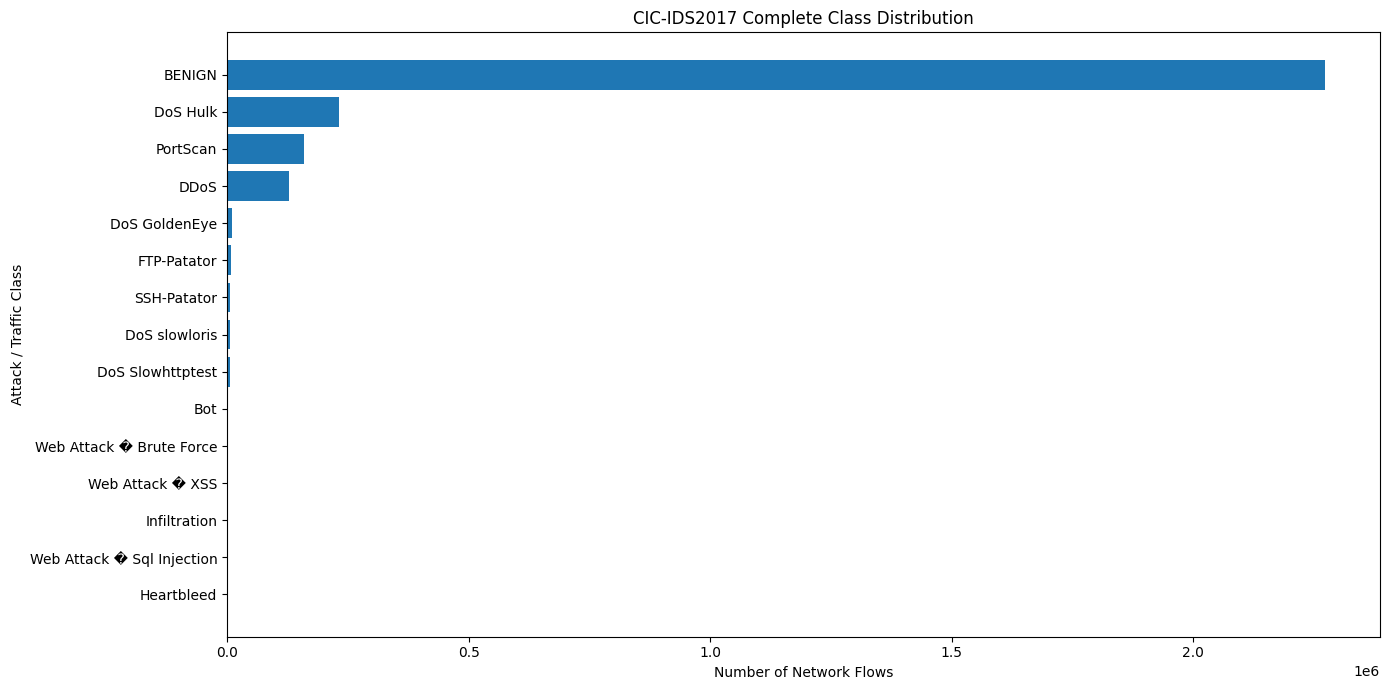

In [38]:
plt.figure(figsize=(14, 7))

plt.barh(
    label_distribution["Label"],
    label_distribution["Count"]
)

plt.xlabel("Number of Network Flows")
plt.ylabel("Attack / Traffic Class")
plt.title("CIC-IDS2017 Complete Class Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [39]:
print("TOTAL FEATURES / COLUMNS:", len(sample_df.columns))
print("=" * 80)

for i, column in enumerate(sample_df.columns, start=1):
    print(f"{i:3}. {repr(column)}")

TOTAL FEATURES / COLUMNS: 79
  1. ' Destination Port'
  2. ' Flow Duration'
  3. ' Total Fwd Packets'
  4. ' Total Backward Packets'
  5. 'Total Length of Fwd Packets'
  6. ' Total Length of Bwd Packets'
  7. ' Fwd Packet Length Max'
  8. ' Fwd Packet Length Min'
  9. ' Fwd Packet Length Mean'
 10. ' Fwd Packet Length Std'
 11. 'Bwd Packet Length Max'
 12. ' Bwd Packet Length Min'
 13. ' Bwd Packet Length Mean'
 14. ' Bwd Packet Length Std'
 15. 'Flow Bytes/s'
 16. ' Flow Packets/s'
 17. ' Flow IAT Mean'
 18. ' Flow IAT Std'
 19. ' Flow IAT Max'
 20. ' Flow IAT Min'
 21. 'Fwd IAT Total'
 22. ' Fwd IAT Mean'
 23. ' Fwd IAT Std'
 24. ' Fwd IAT Max'
 25. ' Fwd IAT Min'
 26. 'Bwd IAT Total'
 27. ' Bwd IAT Mean'
 28. ' Bwd IAT Std'
 29. ' Bwd IAT Max'
 30. ' Bwd IAT Min'
 31. 'Fwd PSH Flags'
 32. ' Bwd PSH Flags'
 33. ' Fwd URG Flags'
 34. ' Bwd URG Flags'
 35. ' Fwd Header Length'
 36. ' Bwd Header Length'
 37. 'Fwd Packets/s'
 38. ' Bwd Packets/s'
 39. ' Min Packet Length'
 40. ' Max Pack

In [40]:
feature_type_summary = pd.DataFrame({
    "Feature": sample_df.columns,
    "Data_Type": sample_df.dtypes.astype(str).values,
    "Unique_Values": [
        sample_df[col].nunique(dropna=True)
        for col in sample_df.columns
    ]
})

print("FEATURE DATA TYPE SUMMARY")
print("=" * 80)

print(feature_type_summary.to_string(index=False))

print("\n" + "=" * 80)
print("DATA TYPE COUNTS")
print("=" * 80)

print(sample_df.dtypes.value_counts())

FEATURE DATA TYPE SUMMARY
                     Feature Data_Type  Unique_Values
            Destination Port     int64            643
               Flow Duration     int64           3729
           Total Fwd Packets     int64             85
      Total Backward Packets     int64            100
 Total Length of Fwd Packets     int64            892
 Total Length of Bwd Packets     int64           1142
       Fwd Packet Length Max     int64            513
       Fwd Packet Length Min     int64             71
      Fwd Packet Length Mean   float64           1028
       Fwd Packet Length Std   float64           1043
       Bwd Packet Length Max     int64            511
       Bwd Packet Length Min     int64            233
      Bwd Packet Length Mean   float64           1268
       Bwd Packet Length Std   float64           1192
                Flow Bytes/s   float64           4194
              Flow Packets/s   float64           3793
               Flow IAT Mean   float64           3791
  

In [41]:
feature_columns = [
    col for col in sample_df.columns
    if col != LABEL_COLUMN
]

constant_features = []

for col in feature_columns:
    if sample_df[col].nunique(dropna=False) <= 1:
        constant_features.append(col)

print("CONSTANT FEATURES IN 5,000-ROW SAMPLE")
print("=" * 80)

if constant_features:
    for feature in constant_features:
        print(repr(feature))
else:
    print("No constant features found.")

print("\nNumber of constant features:", len(constant_features))

CONSTANT FEATURES IN 5,000-ROW SAMPLE
' Bwd PSH Flags'
' Fwd URG Flags'
' Bwd URG Flags'
' RST Flag Count'
' CWE Flag Count'
' ECE Flag Count'
'Fwd Avg Bytes/Bulk'
' Fwd Avg Packets/Bulk'
' Fwd Avg Bulk Rate'
' Bwd Avg Bytes/Bulk'
' Bwd Avg Packets/Bulk'
'Bwd Avg Bulk Rate'

Number of constant features: 12


In [42]:
numeric_summary = sample_df[
    feature_columns
].describe().T

print("NUMERICAL FEATURE STATISTICS")
print("=" * 100)

display(numeric_summary)

NUMERICAL FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Destination Port,5000.0,6.628911e+03,1.693223e+04,0.000000,53.000000,80.000000,443.000000,6.096600e+04
Flow Duration,5000.0,1.106688e+07,2.962341e+07,0.000000,240.750000,49303.500000,502783.000000,1.199947e+08
Total Fwd Packets,5000.0,8.406400e+00,2.765597e+01,1.000000,2.000000,2.000000,7.000000,1.611000e+03
Total Backward Packets,5000.0,8.869600e+00,3.463749e+01,0.000000,1.000000,2.000000,5.000000,1.935000e+03
Total Length of Fwd Packets,5000.0,9.804140e+02,6.562207e+03,0.000000,43.000000,76.000000,388.250000,1.187360e+05
Total Length of Bwd Packets,5000.0,1.045020e+04,6.083711e+04,0.000000,6.000000,168.000000,693.250000,3.433707e+06
Fwd Packet Length Max,5000.0,2.361648e+02,6.128347e+02,0.000000,30.000000,44.000000,197.000000,1.168000e+04
Fwd Packet Length Min,5000.0,2.030860e+01,2.273938e+01,0.000000,0.000000,6.000000,41.000000,2.470000e+02
Fwd Packet Length Mean,5000.0,6.132210e+01,1.666064e+02,0.000000,18.500000,37.000000,50.512500,2.258880e+03
Fwd Packet Length Std,5000.0,6.706772e+01,1.931781e+02,0.000000,0.000000,0.000000,71.172809,2.650906e+03


In [43]:
correlation_matrix = sample_df[feature_columns].corr()

print("Correlation matrix created successfully.")
print("Matrix size:", correlation_matrix.shape)

Correlation matrix created successfully.
Matrix size: (78, 78)


In [44]:
corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_corr_pairs = corr_pairs[
    corr_pairs["Correlation"].abs() >= 0.90
].sort_values(
    by="Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

print("HIGHLY CORRELATED FEATURE PAIRS (|correlation| >= 0.90)")
print("=" * 100)

print(high_corr_pairs.to_string(index=False))

print("\nNumber of highly correlated pairs:", len(high_corr_pairs))

HIGHLY CORRELATED FEATURE PAIRS (|correlation| >= 0.90)
                   Feature_1                    Feature_2  Correlation
           Total Fwd Packets          Subflow Fwd Packets     1.000000
 Total Length of Fwd Packets            Subflow Fwd Bytes     1.000000
      Total Backward Packets          Subflow Bwd Packets     1.000000
 Total Length of Bwd Packets            Subflow Bwd Bytes     1.000000
      Fwd Packet Length Mean         Avg Fwd Segment Size     1.000000
           Fwd Header Length          Fwd Header Length.1     1.000000
      Bwd Packet Length Mean         Avg Bwd Segment Size     1.000000
               Fwd PSH Flags               SYN Flag Count     1.000000
               Flow Duration                Fwd IAT Total     0.998521
              Flow Packets/s                Fwd Packets/s     0.998061
          Packet Length Mean          Average Packet Size     0.997521
                Flow IAT Max                  Fwd IAT Max     0.997175
                   Id

In [45]:
print("=" * 80)
print("        CIC-IDS2017 DATASET EXPLORATION SUMMARY")
print("=" * 80)

print(f"\nTotal CSV files              : {len(csv_files)}")
print(f"Total network flows         : {sum(full_label_counts.values()):,}")
print(f"Total columns               : {len(sample_df.columns)}")
print(f"Input features              : {len(feature_columns)}")
print(f"Target column               : {LABEL_COLUMN}")

print("\nData types:")
print(f"  Integer features          : {(sample_df[feature_columns].dtypes == 'int64').sum()}")
print(f"  Float features            : {(sample_df[feature_columns].dtypes == 'float64').sum()}")

print("\nClasses:")
print(f"  Number of classes         : {len(full_label_counts)}")

print("\nClass distribution:")
for label, count in full_label_counts.most_common():
    percentage = (count / sum(full_label_counts.values())) * 100
    print(f"  {label:<30} {count:>12,} ({percentage:>7.3f}%)")

print("\nData-quality findings:")
print(f"  Infinite-value features   : {len(infinity_summary)}")
print(f"  Constant features*        : {len(constant_features)}")
print(f"  High-correlation pairs*   : {len(high_corr_pairs)}")

print("\n* Constant features and correlations were examined")
print("  on the 5,000-row exploration sample.")

print("\n" + "=" * 80)
print("DATASET EXPLORATION COMPLETE")
print("=" * 80)

        CIC-IDS2017 DATASET EXPLORATION SUMMARY

Total CSV files              : 8
Total network flows         : 2,830,743
Total columns               : 79
Input features              : 78
Target column               :  Label

Data types:
  Integer features          : 54
  Float features            : 24

Classes:
  Number of classes         : 15

Class distribution:
  BENIGN                            2,273,097 ( 80.300%)
  DoS Hulk                            231,073 (  8.163%)
  PortScan                            158,930 (  5.614%)
  DDoS                                128,027 (  4.523%)
  DoS GoldenEye                        10,293 (  0.364%)
  FTP-Patator                           7,938 (  0.280%)
  SSH-Patator                           5,897 (  0.208%)
  DoS slowloris                         5,796 (  0.205%)
  DoS Slowhttptest                      5,499 (  0.194%)
  Bot                                   1,966 (  0.069%)
  Web Attack � Brute Force              1,507 (  0.053%)
  Web